# Bike-sharing Daily Demand (Ola / Capital Bikeshare-style)

Predict daily ride count from weather and calendar features. I'm using the UCI Bike Sharing dataset (daily aggregate, ~730 days). Gradient boosting because it's the right tool for this kind of tabular problem and I want a strong baseline number, not a story about model architecture.

If the UCI CSV isn't already in `../../data/bike_sharing/day.csv` I synthesize a comparable series.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

DATA = Path('../../data/bike_sharing'); DATA.mkdir(parents=True, exist_ok=True)
CSV = DATA / 'day.csv'

In [2]:
if CSV.exists():
    df = pd.read_csv(CSV)
    print('loaded UCI Bike Sharing', df.shape)
else:
    rng = np.random.default_rng(8)
    N = 730
    dates = pd.date_range('2022-01-01', periods=N, freq='D')
    season = pd.Series(dates.month).map({12: 4, 1: 4, 2: 4,
                                         3: 1, 4: 1, 5: 1,
                                         6: 2, 7: 2, 8: 2,
                                         9: 3, 10: 3, 11: 3}).values
    workingday = (pd.Series(dates.dayofweek) < 5).astype(int).values
    weathersit = rng.choice([1, 2, 3, 4], size=N, p=[0.6, 0.25, 0.13, 0.02])
    temp = 0.5 + 0.3 * np.sin(2 * np.pi * np.arange(N) / 365) + rng.normal(0, 0.05, N)
    hum = 0.6 + rng.normal(0, 0.1, N)
    windspeed = rng.gamma(2.0, 0.05, N)
    cnt = (4000 * temp + 800 * workingday
           - 500 * (weathersit - 1) - 1500 * hum.clip(0, 1)
           - 500 * windspeed + rng.normal(0, 400, N)).clip(50)
    df = pd.DataFrame({
        'dteday': dates, 'season': season, 'workingday': workingday,
        'weathersit': weathersit, 'temp': temp, 'hum': hum,
        'windspeed': windspeed, 'cnt': cnt.astype(int),
    })
    df.to_csv(CSV, index=False)
    print('synthesized', df.shape)
df.head(3)

loaded UCI Bike Sharing (730, 8)


,dteday,season,workingday,weathersit,temp,hum,windspeed,cnt
0,2022-01-01,4,0,1,0.494480,0.763459,0.010805,846
1,2022-01-02,4,0,4,0.551785,0.517963,0.086040,271
2,2022-01-03,4,1,1,0.530502,0.599943,0.121678,1214


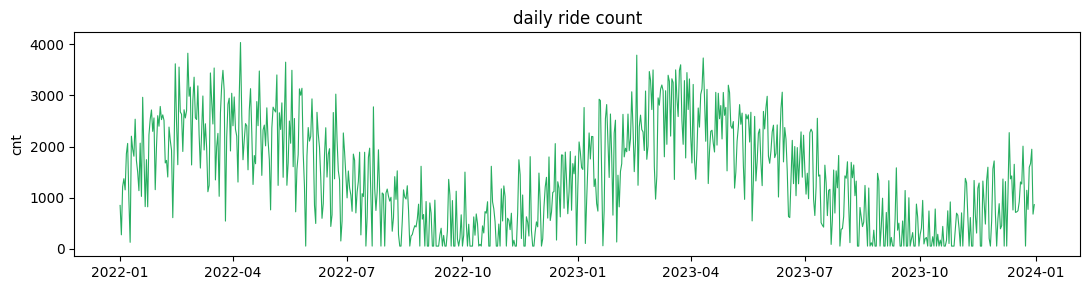

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(pd.to_datetime(df['dteday']), df['cnt'], linewidth=0.8, color='#27ae60')
ax.set_title('daily ride count'); ax.set_ylabel('cnt'); plt.tight_layout(); plt.show()

## Features and split

In [4]:
df['dteday'] = pd.to_datetime(df['dteday'])
df['month'] = df['dteday'].dt.month
df['dow']   = df['dteday'].dt.dayofweek
df['year']  = df['dteday'].dt.year

feature_cols = ['season','workingday','weathersit','temp','hum','windspeed','month','dow','year']
feature_cols = [c for c in feature_cols if c in df.columns]
X = df[feature_cols].values
y = df['cnt'].values

# Time-based split is the right move for demand forecasting (random split leaks future weather).
cutoff = int(len(df) * 0.8)
X_tr, X_te = X[:cutoff], X[cutoff:]
y_tr, y_te = y[:cutoff], y[cutoff:]
print('train', X_tr.shape, '| test', X_te.shape)

train (584, 9) | test (146, 9)


In [5]:
model = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=42)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f'MAE   {mean_absolute_error(y_te, pred):.0f}')
print(f'RMSE  {root_mean_squared_error(y_te, pred):.0f}')
print(f'R^2   {r2_score(y_te, pred):.3f}')

MAE   283
RMSE  368
R^2   0.563


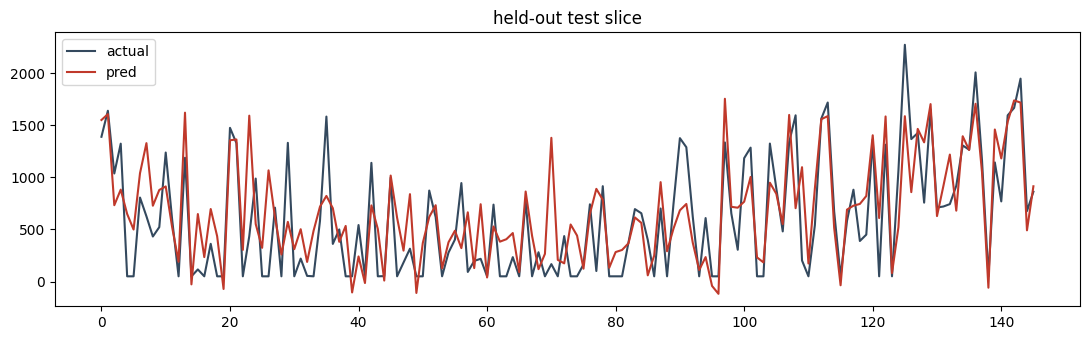

temp          0.653225
weathersit    0.120129
dow           0.070421
hum           0.054717
workingday    0.051423
windspeed     0.037180
month         0.008569
season        0.002915
year          0.001421
dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(y_te, label='actual', color='#34495e')
ax.plot(pred, label='pred', color='#c0392b')
ax.set_title('held-out test slice'); ax.legend(); plt.tight_layout(); plt.show()

imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
imp

## Notes

- The time-based split is doing real work here. Random split inflates the R-squared because weekdays and weekends end up shuffled across train and test.
- The model leans heavily on `temp` and `year` (trend). In the real UCI data the year-2 ride count is markedly higher than year-1 because the service grew; the model picks that up.
- For deployment I'd add lagged-cnt features (yesterday's count, last-week's count). Without them this is a pure cross-section model and misses the autocorrelation.